# 24. Nuclear physics: a half-life from decay counts

**Track:** advanced example &nbsp;·&nbsp; **Uses:** Chapters 6, 7, 14 and 15

**Reading:** Taylor, ch. 8.6 · Bevington & Robinson, Example 8.1 · Knoll,
*Radiation Detection and Measurement*, ch. 3

Measuring a half-life is a standard laboratory exercise: activate a sample,
count its decays in successive intervals, and fit an exponential. The
textbook route plots the logarithm of the background-subtracted counts
against time and fits a straight line (Taylor, ch. 8.6). This example
compares that route with a nonlinear $\chi^2$ fit and with the Poisson
likelihood, on simulated data with a known half-life, and shows that the
choice matters: two of the three common methods give a half-life that is
biased by about one to two standard uncertainties, with error bars that cover
the true value far less often than claimed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(124)

## The experiment

A sample containing a short-lived isotope is placed in front of a counter.
The counts are recorded in 1-minute intervals for 120 minutes, about five
half-lives. Before the sample is brought in, the background is counted for
100 minutes. The counting rate is a few per second at most, so dead time is
negligible (Section 6.4). The half-life is defined by the decay rate alone,
so the detection efficiency cancels.

The next cell is the "apparatus". Skip it on first reading.

In [2]:
# ---- hidden truth of the simulated experiment --------------------------------
T_half_true = 25.0                   # min
A0_true = 150.0                      # initial net rate (counts/min)
b_true = 12.0                        # background rate (counts/min)
t_bg = 100.0                         # min of background counting
edges = np.arange(0, 121.0)          # 1-min counting intervals
t_mid = edges[:-1] + 0.5

def expected(A, lam, b):
    """Expected counts in each interval: decay integrated over the interval, plus background."""
    return A / lam * (np.exp(-lam * edges[:-1]) - np.exp(-lam * edges[1:])) + b * np.diff(edges)

lam_true = np.log(2) / T_half_true

def experiment(rng):
    return rng.poisson(expected(A0_true, lam_true, b_true)), rng.poisson(b_true * t_bg)
# ------------------------------------------------------------------------------

n, n_bg = experiment(rng)
print(f"counts in the first five intervals: {n[:5]}; in the last five: {n[-5:]}")
print(f"background run: {n_bg} counts in {t_bg:.0f} min, rate {n_bg / t_bg:.2f} ± {np.sqrt(n_bg) / t_bg:.2f} per min")

counts in the first five intervals: [171 143 150 142 152]; in the last five: [18 24 16 13 21]
background run: 1162 counts in 100 min, rate 11.62 ± 0.34 per min


After a few half-lives the counts are dominated by the background, and in
the last hour the net counts are a few per interval, often negative after
subtraction.

## Step 1. The textbook method: a straight line through the logarithms

With the background rate $\hat b$ subtracted, the net counts should follow
$n_i - \hat b \approx A e^{-\lambda t_i}$, so $\ln(n_i - \hat b)$ is linear in
$t_i$ with slope $-\lambda$. The uncertainty of $\ln(n_i - \hat b)$ is
$\sqrt{n_i}/(n_i - \hat b)$ (Section 3.1), which gives the weights of a
straight-line fit (Section 11.4). Intervals with $n_i \le \hat b$ have no
logarithm and must be dropped. The half-life is $T_{1/2} = \ln 2/\lambda$.

In [3]:
def fit_loglinear(n, n_bg, t_cut=None):
    b_hat = n_bg / t_bg
    net = n - b_hat
    use = net > 0
    if t_cut is not None:
        use &= t_mid < t_cut
    fit = ep.linear_fit(t_mid[use], np.log(net[use]), np.sqrt(n[use]) / net[use])
    lam, u_lam = -fit.slope, fit.u_slope
    return np.log(2) / lam, np.log(2) / lam**2 * u_lam, use

T_ll, u_ll, used = fit_loglinear(n, n_bg)
print(f"log-linear fit: T1/2 = {T_ll:.2f} ± {u_ll:.2f} min, using {used.sum()} of {n.size} intervals")

log-linear fit: T1/2 = 25.96 ± 0.61 min, using 120 of 120 intervals


## Step 2. A nonlinear least-squares fit

The second method fits the model $\mu_i = \int_{\text{interval } i} A
e^{-\lambda t}\,\mathrm dt + \hat b\,\Delta t$ directly to the counts, with
weights $1/n_i$ (Neyman's $\chi^2$, Section 15.1). It keeps every interval,
and the background enters the model instead of being subtracted.

In [4]:
def fit_neyman(n, n_bg):
    b_hat = n_bg / t_bg
    model = lambda t, A, lam: expected(A, lam, b_hat)
    f = ep.nonlinear_fit(model, t_mid, n, np.sqrt(np.maximum(n, 1)), [100.0, 0.02])
    lam, u_lam = f.params[1], f.errors[1]
    return np.log(2) / lam, np.log(2) / lam**2 * u_lam

T_ny, u_ny = fit_neyman(n, n_bg)
print(f"Neyman chi2 fit: T1/2 = {T_ny:.2f} ± {u_ny:.2f} min")

Neyman chi2 fit: T1/2 = 24.48 ± 0.56 min


## Step 3. The Poisson likelihood

The third method writes down the probability of everything that was
observed: the counts $n_i$ in the decay run, each Poisson with mean $\mu_i(A,
\lambda, b)$, and the count $n_b$ of the background run, Poisson with mean
$b\,t_\text{bg}$. The background rate is now a parameter, determined jointly
by the background run and by the tail of the decay curve, and its
uncertainty propagates into $\lambda$ automatically. The uncertainty comes
from the Fisher information, and the interval is checked with the profile
likelihood (Section 14.3).

In [5]:
def nll(q, n, n_bg):
    A, lam, b = q
    if A <= 0 or lam <= 0 or b <= 0:
        return np.inf
    mu = expected(A, lam, b)
    return np.sum(mu - n * np.log(mu)) + b * t_bg - n_bg * np.log(b * t_bg)

def fisher_cov(q):
    mu = np.r_[expected(*q), q[2] * t_bg]
    J = np.empty((mu.size, 3))
    for k in range(3):
        h = 1e-6 * q[k]; dq = np.zeros(3); dq[k] = h
        J[:-1, k] = (expected(*(q + dq)) - expected(*(q - dq))) / (2 * h)
        J[-1, k] = t_bg if k == 2 else 0.0
    return np.linalg.inv(J.T @ (J / mu[:, None]))

def fit_poisson(n, n_bg):
    q0 = [100.0, 0.02, max(n_bg / t_bg, 0.1)]
    sol = optimize.minimize(nll, q0, args=(n, n_bg), method="Nelder-Mead",
                            options=dict(xatol=1e-10, fatol=1e-10, maxiter=5000))
    q = sol.x
    lam, u_lam = q[1], np.sqrt(fisher_cov(q)[1, 1])
    return np.log(2) / lam, np.log(2) / lam**2 * u_lam, q, sol.fun

T_ml, u_ml, q_ml, nll_min = fit_poisson(n, n_bg)
print(f"Poisson likelihood: T1/2 = {T_ml:.2f} ± {u_ml:.2f} min;  background {q_ml[2]:.2f} per min")

def profile_T(T, n, n_bg, q_start):
    lam = np.log(2) / T
    f = lambda ab: nll([ab[0], lam, ab[1]], n, n_bg)
    return optimize.minimize(f, [q_start[0], q_start[2]], method="Nelder-Mead",
                             options=dict(xatol=1e-10, fatol=1e-10)).fun - nll_min

T_grid = T_ml + u_ml * np.linspace(-3, 3, 41)
prof = np.array([profile_T(T, n, n_bg, q_ml) for T in T_grid])
g = lambda T: profile_T(T, n, n_bg, q_ml) - 0.5
lo, hi = optimize.brentq(g, T_ml - 3 * u_ml, T_ml), optimize.brentq(g, T_ml, T_ml + 3 * u_ml)
print(f"profile likelihood interval: {T_ml:.2f} -{T_ml - lo:.2f} +{hi - T_ml:.2f} min")

Poisson likelihood: T1/2 = 24.99 ± 0.61 min;  background 11.63 per min


profile likelihood interval: 24.99 -0.60 +0.62 min


For this data set the three methods give different answers, differing by
more than their stated uncertainties. One data set cannot say which is
right, but the simulation can be repeated.

## Step 4. Which method can be trusted?

The cell repeats the whole experiment 1000 times and applies each method,
plus two common variants: the log-linear fit restricted to the first 50
minutes, where the counts are high, and a likelihood fit that ignores the
background altogether.

In [6]:
def fit_no_background(n):
    f = lambda q: np.inf if min(q) <= 0 else np.sum(expected(q[0], q[1], 0) - n * np.log(expected(q[0], q[1], 0)))
    return np.log(2) / optimize.minimize(f, [100.0, 0.02], method="Nelder-Mead").x[1]

methods = ["log-linear", "log-linear, first 50 min", "Neyman chi2", "Poisson likelihood"]
sims = {m: [] for m in methods}
T_nobg = []
for _ in range(1000):
    nn, nb = experiment(rng)
    sims["log-linear"].append(fit_loglinear(nn, nb)[:2])
    sims["log-linear, first 50 min"].append(fit_loglinear(nn, nb, t_cut=50)[:2])
    sims["Neyman chi2"].append(fit_neyman(nn, nb))
    sims["Poisson likelihood"].append(fit_poisson(nn, nb)[:2])
    T_nobg.append(fit_no_background(nn))
sims = {m: np.array(v) for m, v in sims.items()}

print(f"true half-life {T_half_true} min; 1000 simulated experiments")
print("method                       mean T1/2   bias/scatter   scatter   mean stated u   coverage of ±u")
for m in methods:
    T, u = sims[m][:, 0], sims[m][:, 1]
    print(f"{m:26s}   {T.mean():7.2f}       {(T.mean() - T_half_true) / T.std():+5.2f}       {T.std():5.2f}       {u.mean():5.2f}"
          f"          {np.mean(np.abs(T - T_half_true) < u):.2f}")
print(f"likelihood ignoring the background: mean T1/2 = {np.mean(T_nobg):.1f} min")

true half-life 25.0 min; 1000 simulated experiments
method                       mean T1/2   bias/scatter   scatter   mean stated u   coverage of ±u
log-linear                     26.42       +2.19        0.65        0.63          0.10
log-linear, first 50 min       25.39       +0.34        1.14        1.15          0.67
Neyman chi2                    24.33       -1.05        0.64        0.56          0.40
Poisson likelihood             25.03       +0.05        0.62        0.62          0.67
likelihood ignoring the background: mean T1/2 = 34.2 min


The results separate the methods clearly.

* **Log-linear over the whole run** is biased high by about two standard
  deviations, and its error bar covers the true value in only about one
  experiment in ten. The main cause is the weights. They are computed from
  the observed counts, $(n_i - \hat b)^2/n_i$, so an interval in the tail that
  happened to fluctuate upwards gets a larger weight than one that
  fluctuated downwards. The tail is pulled up, the line flattens, and the
  half-life comes out long. A second effect acts the other way: the
  logarithm of a small noisy number is biased low (Section 12.3). With
  weights computed from the expected instead of the observed counts, this
  second effect dominates and the half-life comes out about one standard
  deviation *short* (Exercise 5). The rare intervals with $n_i \le \hat b$
  that must be dropped add a little to the upward bias.
* **Log-linear over the first 50 minutes** is nearly unbiased, because the
  counts there are large, but it throws away information: its scatter is
  almost twice that of the likelihood fit.
* **Neyman's $\chi^2$** is biased low by about one standard deviation, for the
  reason found in Section 15.1: weights $1/n_i$ favour intervals that
  fluctuated downwards.
* The **Poisson likelihood** is unbiased, its stated uncertainty equals the
  actual scatter, and its coverage is close to 68 %. It is also the most
  precise of the four.
* Ignoring the background altogether is the worst error of all: it gives a
  half-life about 40 % too long.

None of the faulty methods gives any warning sign in a single experiment:
each returns a plausible half-life with a plausible error bar.

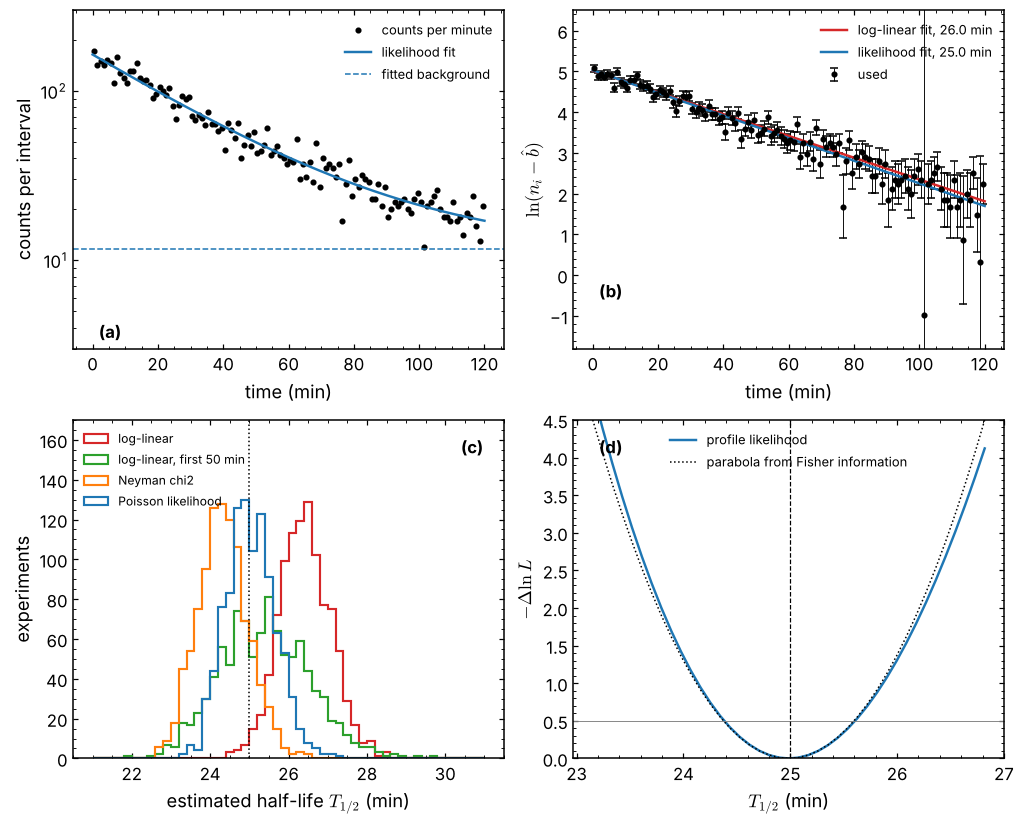

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
ax.semilogy(t_mid, np.maximum(n, 0.5), "o", ms=3, color="k", label="counts per minute")
tf = np.linspace(0, 120, 400)
ax.semilogy(tf, q_ml[0] * np.exp(-q_ml[1] * tf) + q_ml[2], "C0", label="likelihood fit")
ax.axhline(q_ml[2], color="C0", ls="--", lw=1, label="fitted background")
ax.set_xlabel("time (min)"); ax.set_ylabel("counts per interval")
ax.set_ylim(3, 300); ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(a)", x=0.06, y=0.08)

ax = axes[0, 1]
b_hat = n_bg / t_bg
net = n - b_hat
ax.errorbar(t_mid[used], np.log(net[used]), np.sqrt(n[used]) / net[used], fmt="o", ms=3, color="k", lw=0.6,
            label="used")
if (~used).any():
    ax.plot(t_mid[~used], np.full((~used).sum(), -1.4), "x", color="C3", ms=5, label=r"dropped ($n_i \leq \hat b$)")
lam_ll = np.log(2) / T_ll
fit_ll = ep.linear_fit(t_mid[used], np.log(net[used]), np.sqrt(n[used]) / net[used])
ax.plot(tf, fit_ll.intercept + fit_ll.slope * tf, "C3", label=f"log-linear fit, {T_ll:.1f} min")
ax.plot(tf, np.log(q_ml[0]) - q_ml[1] * tf, "C0", label=f"likelihood fit, {T_ml:.1f} min")
ax.set_xlabel("time (min)"); ax.set_ylabel(r"$\ln(n_i - \hat b)$")
ax.set_ylim(-1.8, 6.5); ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(b)", x=0.06, y=0.2)

ax = axes[1, 0]
bins = np.linspace(21, 31, 51)
for m, c in zip(methods, ("C3", "C2", "C1", "C0")):
    ax.hist(sims[m][:, 0], bins, histtype="step", lw=1.4, color=c, label=m)
ax.axvline(T_half_true, color="k", ls=":", lw=1)
ax.set_xlabel(r"estimated half-life $T_{1/2}$ (min)"); ax.set_ylabel("experiments")
ax.set_ylim(0, 170); ax.legend(loc="upper left", fontsize=8); ep.panel_label(ax, "(c)", x=0.9)

ax = axes[1, 1]
ax.plot(T_grid, prof, "C0", label="profile likelihood")
ax.plot(T_grid, 0.5 * ((T_grid - T_ml) / u_ml)**2, "k:", lw=1, label="parabola from Fisher information")
ax.axhline(0.5, color="0.5", lw=0.6)
ax.axvline(T_half_true, color="k", ls="--", lw=0.8)
ax.set_xlabel(r"$T_{1/2}$ (min)"); ax.set_ylabel(r"$-\Delta\ln L$")
ax.set_ylim(0, 4.5); ax.legend(loc="upper center", fontsize=8.5); ep.panel_label(ax, "(d)", x=0.06)
plt.show()

**(a)** The counts of one experiment with the likelihood fit. **(b)** The same
data in the textbook representation (in this experiment no interval has
$n_i \le \hat b$, so none is dropped). **(c)** Half-lives from 1000 simulated experiments for four methods;
dotted: the true value. **(d)** Profile likelihood of the half-life for the
experiment in (a), with the parabola implied by the Fisher information;
dashed: the true value.

## What this example teaches

* The logarithmic straight line is a good way to *look* at decay data and a
  poor way to *fit* them when the counts become small.
* Background must be in the model, and its own measurement belongs in the
  likelihood; then its uncertainty propagates without further effort.
* A method can be checked only by simulation: run the analysis on many
  synthetic data sets with a known answer, and compare bias, scatter,
  stated uncertainty and coverage. That is cheap, and it is the only test
  that catches the failures above.

## Exercises

1. Vary the cut of the restricted log-linear fit from 20 to 120 minutes and
   plot its bias and scatter. Is there a best cut?
2. Count the background for 20 minutes instead of 100. How does the
   uncertainty of the half-life change? What background time would you
   choose, given a fixed total time of four hours?
3. Add a second isotope with a half-life of 2.4 min and 50 % of the initial
   activity (compare Bevington's Example 8.1). Which methods still work?
4. Reduce $A_0$ to 40 counts per minute. How do the four methods compare
   now?
5. Repeat the log-linear fit with weights computed from the fitted curve
   instead of the observed counts (iterate the fit twice). Confirm that the
   bias changes sign, and explain why.

---

**Previous:** [23. Molecular simulation: pressure and diffusion in a Lennard-Jones liquid](23_md_lennard_jones.ipynb) &nbsp;·&nbsp; **Next:** [25. Analytical chemistry: a calibration curve and its detection limit](25_calibration_curve_detection_limit.ipynb)